# Credit risk scoring project

### 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

### 2. Data cleaning and preparation

In [2]:
df = pd.read_csv("CreditScoring.csv")

In [3]:
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [4]:
df.T

,0,1,2,3,4,5,6,7,8,9,...,4445,4446,4447,4448,4449,4450,4451,4452,4453,4454
Status,1,1,2,1,1,1,1,1,1,2,...,2,1,1,1,2,2,1,2,1,1
Seniority,9,17,10,0,0,1,29,9,0,0,...,6,23,6,3,1,1,22,0,0,5
Home,1,1,2,1,1,2,2,5,2,5,...,5,2,2,2,6,1,2,2,1,2
Time,60,60,36,60,36,60,60,12,60,48,...,60,60,48,60,48,60,60,24,48,60
Age,30,58,46,24,26,36,44,27,32,41,...,22,50,52,49,30,39,46,37,23,32
Marital,2,3,2,1,1,2,2,1,2,2,...,1,2,2,2,2,2,2,2,1,2
Records,1,1,2,1,1,1,1,1,1,1,...,2,2,1,1,2,1,1,1,1,1
Job,3,1,3,1,1,1,1,1,3,2,...,1,3,1,1,2,1,1,2,3,3
Expenses,73,48,90,63,46,75,75,35,90,90,...,35,90,45,35,75,69,60,60,49,60
Income,129,131,200,182,107,214,125,80,107,80,...,100,69,190,160,77,92,75,90,140,140


In [5]:
df.columns = df.columns.str.lower()

In [6]:
df.columns

Index(['status', 'seniority', 'home', 'time', 'age', 'marital', 'records',
       'job', 'expenses', 'income', 'assets', 'debt', 'amount', 'price'],
      dtype='str')

In [7]:
df.status.value_counts()

status
1    3200
2    1254
0       1
Name: count, dtype: int64

In [8]:
status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}

df.status = df.status.map(status_values)

home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

In [9]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [10]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


In [11]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [12]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


In [13]:
df[df.status == 'unk']

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
3309,unk,10,private,60,25,single,no,fixed,35,148.0,3000.0,0.0,1500,1888


In [14]:
df = df[df.status != 'unk'].reset_index(drop=True)

In [15]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

In [16]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [17]:
y_train = (df_train.status == 'default').astype(int).values
y_val = (df_val.status == 'default').astype(int).values
y_test = (df_test.status == 'default').astype(int).values

In [18]:
del df_train['status']
del df_val['status']
del df_test['status']

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline

In [20]:
for col in df.columns:
    print("column name:", col)
    print("type:", df[col].dtypes)
    print(df[col].unique())
    print("-----------------")

column name: status
type: str
<StringArray>
['ok', 'default']
Length: 2, dtype: str
-----------------
column name: seniority
type: int64
[ 9 17 10  0  1 29  6  7  8 19 15 33  2  5 27 26 12  3  4 14 32 30 24 25
 22 18 11 38 13 20 16 40 23 21 35 37 31 43 28 36 41 45 42 48 47 39 34]
-----------------
column name: home
type: str
<StringArray>
['rent', 'owner', 'parents', 'private', 'other', 'ignore', 'unk']
Length: 7, dtype: str
-----------------
column name: time
type: int64
[60 36 12 48 18 24 54 30 42  6 72]
-----------------
column name: age
type: int64
[30 58 46 24 26 36 44 27 32 41 34 29 37 21 68 52 31 25 22 45 51 54 43 23
 39 35 62 56 64 42 61 49 47 28 63 55 40 53 38 57 33 66 50 48 59 60 19 65
 20 18]
-----------------
column name: marital
type: str
<StringArray>
['married', 'widow', 'single', 'separated', 'divorced', 'unk']
Length: 6, dtype: str
-----------------
column name: records
type: str
<StringArray>
['no', 'yes']
Length: 2, dtype: str
-----------------
column name: job
type:

In [21]:
numerical = ['seniority', 'time', 'age', 'expenses', 'income', 'assets', 'debt', 'amount', 'price']

In [22]:
categorical = ['home', 'marital', 'records', 'job']

In [23]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])

### 3. Decision Tree

In [24]:
from sklearn.tree import DecisionTreeClassifier

In [25]:
pipeline = make_pipeline(
    preprocessor,
    DecisionTreeClassifier(max_depth=3)
)

In [26]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [27]:
scores = cross_val_score(
    pipeline, df_train[numerical + categorical], y_train,
    cv=cv,
    scoring="roc_auc"
)

In [28]:
print("AUC per fold:", scores)
print(f"AUC mean: {scores.mean():.3f}")
print(f"Standard deviation: {scores.std():.3f}")

AUC per fold: [0.75156707 0.75278198 0.76124488 0.72570965 0.75641682]
AUC mean: 0.750
Standard deviation: 0.012


In [29]:
from sklearn.model_selection import GridSearchCV

In [30]:
param_grid = {
    "decisiontreeclassifier__max_depth": [5, 6, 7, 8, 9, 10, 12],
    "decisiontreeclassifier__min_samples_leaf": [20, 30, 40, 50, 60, 80, 100, 150]
}

In [31]:
search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    refit=True
)

In [32]:
search.fit(df_train[numerical + categorical], y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ax_depth=3))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'decisiontreeclassifier__max_depth': [5, 6, ...], 'decisiontreeclassifier__min_samples_leaf': [20, 30, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable a

In [33]:
print("Best max_depth:", search.best_params_["decisiontreeclassifier__max_depth"])
print("Best min_samples_leaf:", search.best_params_["decisiontreeclassifier__min_samples_leaf"])
print(f"Best mean AUC: {search.best_score_:.3f}")

Best max_depth: 12
Best min_samples_leaf: 50
Best mean AUC: 0.787


In [34]:
model = search.best_estimator_

In [35]:
y_pred = model.predict_proba(df_val[numerical + categorical])[:,1]

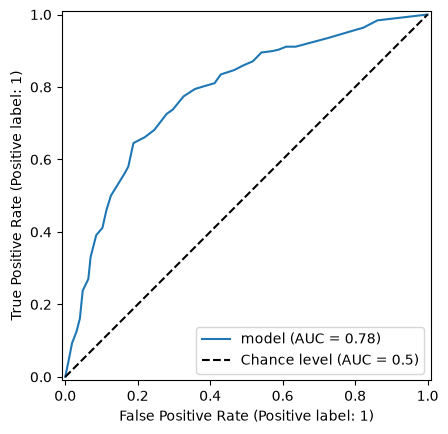

In [36]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_predictions(y_val, y_pred, name="model", plot_chance_level=True)

In [37]:
y_pred = model.predict(df_val[numerical + categorical])

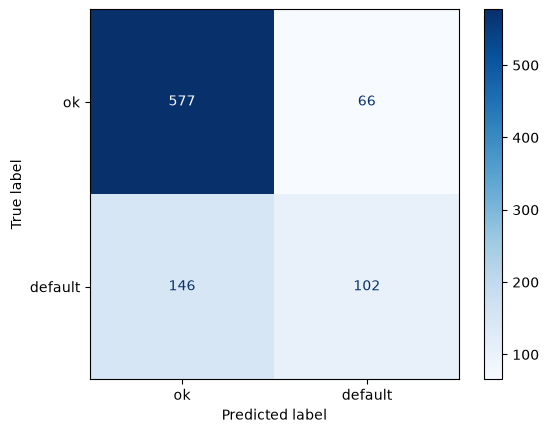

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=["ok", "default"],
    cmap="Blues",
    #values_format="d"
)

<Axes: xlabel='param_decisiontreeclassifier__max_depth', ylabel='param_decisiontreeclassifier__min_samples_leaf'>

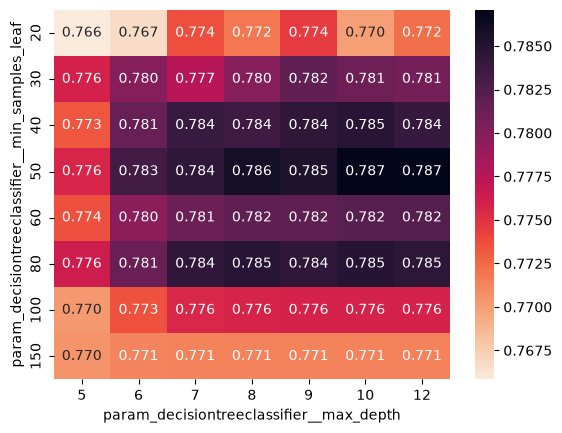

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

results = pd.DataFrame(search.cv_results_)

heatmap_data = results.pivot(index="param_decisiontreeclassifier__min_samples_leaf",
                             columns="param_decisiontreeclassifier__max_depth",
                             values="mean_test_score")

sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="rocket_r")

### 4. Random Forest

In [40]:
from sklearn.ensemble import RandomForestClassifier

In [41]:
pipeline = make_pipeline(
    preprocessor,
    RandomForestClassifier()
)

In [42]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [43]:
scores = cross_val_score(
    pipeline, df_train[numerical + categorical], y_train,
    cv=cv,
    scoring="roc_auc"
)

In [44]:
print("AUC per fold:", scores)
print(f"AUC mean: {scores.mean():.3f}")
print(f"Standard deviation: {scores.std():.3f}")

AUC per fold: [0.82264852 0.83686657 0.83591654 0.82075272 0.82047027]
AUC mean: 0.827
Standard deviation: 0.007


In [45]:
param_grid = {
    "randomforestclassifier__n_estimators": [5, 10, 15, 25, 35],
    "randomforestclassifier__max_depth": [5, 6, 7, 8, 9, 10, 12],
    "randomforestclassifier__min_samples_leaf": [20, 30, 40, 50, 60, 80, 100, 150]
}

In [46]:
search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    refit=True
)

In [47]:
search.fit(df_train[numerical + categorical], y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'randomforestclassifier__max_depth': [5, 6, ...], 'randomforestclassifier__min_samples_leaf': [20, 30, ...], 'randomforestclassifier__n_estimators': [5, 10, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated

In [48]:
print("Best n_estimator:", search.best_params_["randomforestclassifier__n_estimators"])
print("Best max_depth:", search.best_params_["randomforestclassifier__max_depth"])
print("Best min_samples_leaf:", search.best_params_["randomforestclassifier__min_samples_leaf"])
print(f"Best mean AUC: {search.best_score_:.3f}")

Best n_estimator: 35
Best max_depth: 9
Best min_samples_leaf: 20
Best mean AUC: 0.835


In [49]:
model = search.best_estimator_

In [50]:
y_pred = model.predict_proba(df_val[numerical + categorical])[:,1]

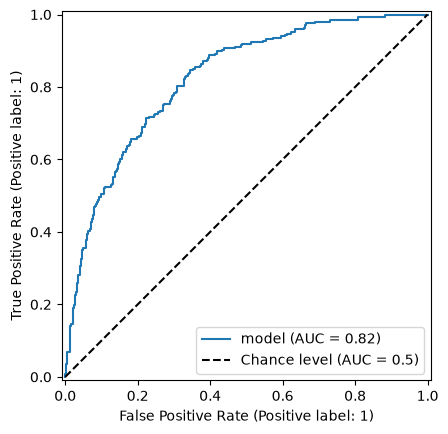

In [51]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_predictions(y_val, y_pred, name="model", plot_chance_level=True)

In [52]:
y_pred = model.predict(df_val[numerical + categorical])

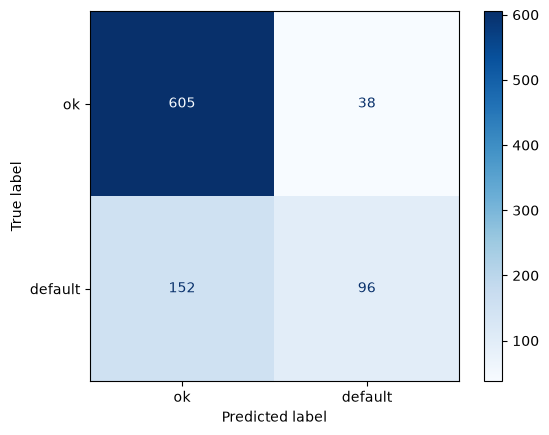

In [53]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=["ok", "default"],
    cmap="Blues",
)

In [54]:
results = pd.DataFrame(search.cv_results_)

<Axes: xlabel='param_randomforestclassifier__n_estimators', ylabel='mean_test_score'>

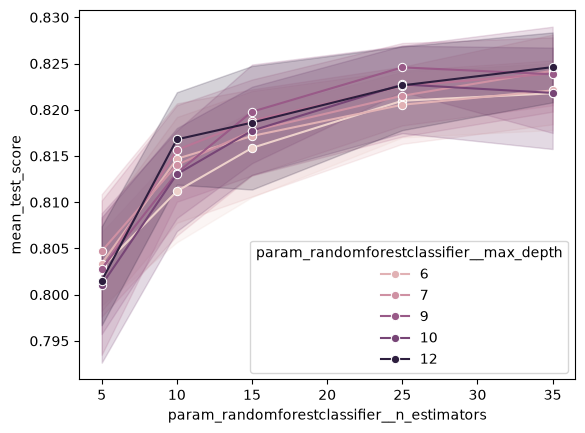

In [55]:
sns.lineplot(
    data=results,
    x="param_randomforestclassifier__n_estimators",
    y="mean_test_score",
    hue="param_randomforestclassifier__max_depth",
    marker="o"
)

### 4. XGBoost

In [56]:
from xgboost import XGBClassifier

In [57]:
pipeline = make_pipeline(
    preprocessor,
    XGBClassifier()
)

In [58]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [59]:
scores = cross_val_score(
    pipeline, df_train[numerical + categorical], y_train,
    cv=cv,
    scoring="roc_auc"
)

In [60]:
print("AUC per fold:", scores)
print(f"AUC mean: {scores.mean():.3f}")
print(f"Standard deviation: {scores.std():.3f}")

AUC per fold: [0.80047188 0.82320316 0.8181754  0.8166396  0.81459187]
AUC mean: 0.815
Standard deviation: 0.008


In [68]:
param_grid = {
    "xgbclassifier__n_estimators": [100, 200, 300],
    "xgbclassifier__learning_rate": [0.1, 0.01],
    "xgbclassifier__max_depth": [3, 5, 7]
}

In [69]:
search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    refit=True
)

In [70]:
search.fit(df_train[numerical + categorical], y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'xgbclassifier__learning_rate': [0.1, 0.01], 'xgbclassifier__max_depth': [3, 5, ...], 'xgbclassifier__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 

In [71]:
print("Best learning_rate:", search.best_params_["xgbclassifier__learning_rate"])
print(f"Best mean AUC: {search.best_score_:.3f}")

Best learning_rate: 0.1
Best mean AUC: 0.840
